In [ ]:
#!pip -q install torch numpy matplotlib

In [ ]:
import time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'; print('Urządzenie:', DEVICE)

Urządzenie: cpu


In [ ]:
def gen(N, L):
    val = np.random.rand(N, L, 1).astype(np.float32)
    mark = np.zeros((N, L, 1), np.float32)
    y = np.zeros((N, 1), np.float32)
    for i in range(N):
        p = np.random.choice(range(8,L), 2, replace=False)
        mark[i, p, 0] = 1.0
        y[i, 0] = val[i, p-8, 0].sum()
    x = np.concatenate([val, mark], axis=2)
    return torch.tensor(x).to(DEVICE), torch.tensor(y).to(DEVICE)

xx, yy = gen(1, 20)
poz = np.where(xx[0, :, 1].cpu().numpy() == 1)[0]
poz_wartosci = poz - 8
print('Pozycje znaczników:', poz + 1)
print('Pozycje wskazywanych wartości:', poz_wartosci + 1)
print('Wartości pod wskazanymi pozycjami:', xx[0, poz_wartosci, 0].cpu().numpy().round(3))
print('Suma (cel):', float(yy[0, 0]))

Pozycje znaczników: [13 18]
Pozycje wskazywanych wartości: [ 5 10]
Wartości pod wskazanymi pozycjami: [0.424 0.383]
Suma (cel): 0.8070963025093079


In [ ]:
class RNNNet(nn.Module):
    def __init__(self, typ, hidden=64):
        super().__init__()
        self.rnn={'RNN':nn.RNN,'LSTM':nn.LSTM,'GRU':nn.GRU}[typ](2,hidden,batch_first=True)
        self.fc=nn.Linear(hidden,1)
    def forward(self,x):
        out,_=self.rnn(x); return self.fc(out[:,-1,:])

class ConvNet(nn.Module):
   def __init__(self, ch=64, dilations=[1, 2, 4]):
       super().__init__()
       layers = []
       in_channels = 2
       for d in dilations:
           layers.append(nn.Conv1d(in_channels, ch, 3, padding=d, dilation=d))
           layers.append(nn.ReLU())
           in_channels = ch
       self.net = nn.Sequential(*layers)
       self.fc = nn.Linear(ch, 1)
   def forward(self, x):
       h = self.net(x.transpose(1, 2)).mean(dim=2)
       return self.fc(h)

def licz_parametry(m): return sum(p.numel() for p in m.parameters())

In [ ]:
def pole_recepcyjne(kernel_size, dilations):
    return 1 + (kernel_size - 1) * sum(dilations)

rf_oryginalny = pole_recepcyjne(3, [1, 2, 4])
rf_zmieniony = pole_recepcyjne(3, [1, 1, 1])

print("Pole recepcyjne dla [1, 2, 4]:", rf_oryginalny)
print("Pole recepcyjne dla [1, 1, 1]:", rf_zmieniony)
print("Odległość znacznika od wskazywanej próbki: 8")

print("Czy [1, 2, 4] obejmuje obie pozycje?",
      rf_oryginalny >= 9)
print("Czy [1, 1, 1] obejmuje obie pozycje?",
      rf_zmieniony >= 9)

Pole recepcyjne dla [1, 2, 4]: 15
Pole recepcyjne dla [1, 1, 1]: 7
Odległość znacznika od wskazywanej próbki: 8
Czy [1, 2, 4] obejmuje obie pozycje? True
Czy [1, 1, 1] obejmuje obie pozycje? False


In [ ]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=5e-3, batch=128):
    model=model.to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=lr); Lf=nn.MSELoss()
    N=Xtr.shape[0]
    t0=time.time()
    for ep in range(epoki):
        model.train(); perm=torch.randperm(N)
        for i in range(0,N,batch):
            idx=perm[i:i+batch]; opt.zero_grad()
            Lf(model(Xtr[idx]),Ytr[idx]).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
    czas=time.time()-t0
    model.eval()
    with torch.no_grad(): mse=Lf(model(Xte),Yte).item()
    return mse, czas

In [ ]:
L = 50
Xtr, Ytr = gen(4000, L)
Xte, Yte = gen(800, L)
mean_y = Ytr.mean().item()
mse_baseline = torch.mean((Yte - mean_y)**2).item()
print(f'Stała predykcja (Baseline) MSE = {mse_baseline:.4f}\n')
modele = {
   'SimpleRNN': RNNNet('RNN'),
   'LSTM': RNNNet('LSTM'),
   'GRU': RNNNet('GRU'),
   'Conv1D': ConvNet(ch=64, dilations=[1, 2, 4])
}
wyniki = {}
for nazwa, m in modele.items():
   mse, czas = trenuj(m, Xtr, Ytr, Xte, Yte)
   wyniki[nazwa] = {'mse': mse, 'czas': czas, 'params': licz_parametry(m)}
   print(f'{nazwa:15s}  MSE={mse:.4f}  czas={czas:4.1f}s  params={licz_parametry(m)}')

Stała predykcja (Baseline) MSE = 0.1598

SimpleRNN        MSE=0.1597  czas=13.5s  params=4417
LSTM             MSE=0.1602  czas=40.4s  params=17473
GRU              MSE=0.0397  czas=38.2s  params=13121
Conv1D           MSE=0.1596  czas=35.0s  params=25217


L=100 ze zmianami

In [ ]:
L = 100
Xtr, Ytr = gen(4000, L)
Xte, Yte = gen(800, L)
mean_y = Ytr.mean().item()
mse_baseline = torch.mean((Yte - mean_y)**2).item()
print(f'Stała predykcja (Baseline) MSE = {mse_baseline:.4f}\n')
modele = {
   'SimpleRNN': RNNNet('RNN'),
   'LSTM': RNNNet('LSTM'),
   'GRU': RNNNet('GRU'),
   'Conv1D': ConvNet(ch=64, dilations=[1, 2, 4]),
   'Conv1D_2': ConvNet(ch=64, dilations=[1, 1, 1]),
   'SimpleRNN_2': RNNNet('RNN', hidden=32)
}
wyniki = {}
for nazwa, m in modele.items():
   mse, czas = trenuj(m, Xtr, Ytr, Xte, Yte)
   wyniki[nazwa] = {'mse': mse, 'czas': czas, 'params': licz_parametry(m)}
   print(f'{nazwa:15s}  MSE={mse:.4f}  czas={czas:4.1f}s  params={licz_parametry(m)}')

Stała predykcja (Baseline) MSE = 0.1667

SimpleRNN        MSE=0.1678  czas=64.2s  params=4417
LSTM             MSE=0.1674  czas=91.6s  params=17473
GRU              MSE=0.1642  czas=75.2s  params=13121
Conv1D           MSE=0.1641  czas=67.0s  params=25217
Conv1D_2         MSE=0.1652  czas=57.4s  params=25217
SimpleRNN_2      MSE=0.1669  czas=15.4s  params=1185


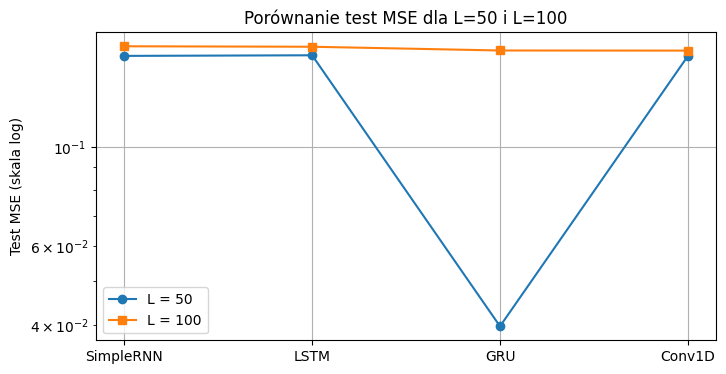

In [ ]:
architektury = ['SimpleRNN', 'LSTM', 'GRU', 'Conv1D']
mse_50 = [0.1597, 0.1602, 0.0397, 0.1596]
mse_100 = [0.1678, 0.1674, 0.1642, 0.1641]

plt.figure(figsize=(8, 4))
plt.plot(architektury, mse_50, marker='o', label='L = 50')
plt.plot(architektury, mse_100, marker='s', label='L = 100')
plt.yscale('log')
plt.ylabel('Test MSE (skala log)')
plt.title('Porównanie test MSE dla L=50 i L=100')
plt.legend()
plt.grid(True)
plt.show()